In [1]:
!pip install pytorch-tabnet imbalanced-learn

In [2]:
import torch
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.neural_network import MLPClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
from google.colab import files

In [15]:
uploaded = files.upload()
file_path = list(uploaded.keys())[0]

Saving dl dataset.xls to dl dataset (1).xls


In [4]:
data = pd.read_csv(file_path)
print("\nShape:", data.shape)
print("\nColumns:", data.columns)
print("\nMissing values:\n", data.isnull().sum())


Shape: (1054, 19)

Columns: Index(['Case_No', 'A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10',
       'Age_Mons', 'Qchat-10-Score', 'Sex', 'Ethnicity', 'Jaundice',
       'Family_mem_with_ASD', 'Who completed the test', 'Class/ASD Traits '],
      dtype='object')

Missing values:
 Case_No                   0
A1                        0
A2                        0
A3                        0
A4                        0
A5                        0
A6                        0
A7                        0
A8                        0
A9                        0
A10                       0
Age_Mons                  0
Qchat-10-Score            0
Sex                       0
Ethnicity                 0
Jaundice                  0
Family_mem_with_ASD       0
Who completed the test    0
Class/ASD Traits          0
dtype: int64


In [5]:
if 'Case_No' in data.columns:
    data.drop('Case_No', axis=1, inplace=True)

data = data.ffill()

data.rename(columns={
'A1':'Q1','A2':'Q2','A3':'Q3','A4':'Q4','A5':'Q5',
'A6':'Q6','A7':'Q7','A8':'Q8','A9':'Q9','A10':'Q10',
'Age_Mons':'Age',
'Family_mem_with_ASD':'Family_ASD',
'Who_completed_the_test':'Screener',
'Class/ASD Traits ':'ASD'
}, inplace=True)

print("\nColumns after renaming:\n", data.columns)


Columns after renaming:
 Index(['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Age',
       'Qchat-10-Score', 'Sex', 'Ethnicity', 'Jaundice', 'Family_ASD',
       'Who completed the test', 'ASD'],
      dtype='object')


In [6]:
for col in data.select_dtypes(include='object').columns:
    data[col] = LabelEncoder().fit_transform(data[col].astype(str))
print("\nAfter Encoding:\n", data.head())


After Encoding:
    Q1  Q2  Q3  Q4  Q5  Q6  Q7  Q8  Q9  Q10  Age  Qchat-10-Score  Sex  \
0   0   0   0   0   0   0   1   1   0    1   28               3    0   
1   1   1   0   0   0   1   1   0   0    0   36               4    1   
2   1   0   0   0   0   0   1   1   0    1   36               4    1   
3   1   1   1   1   1   1   1   1   1    1   24              10    1   
4   1   1   0   1   1   1   1   1   1    1   20               9    0   

   Ethnicity  Jaundice  Family_ASD  Who completed the test  ASD  
0          8         1           0                       4    0  
1          5         1           0                       4    1  
2          8         1           0                       4    1  
3          0         0           0                       4    1  
4          5         0           1                       4    1  


In [7]:
if 'Age' in data.columns:
    scaler = StandardScaler()
    data['Age'] = scaler.fit_transform(data[['Age']])
    print("\nScaled Age:\n", data['Age'].head())


Scaled Age:
 0    0.016652
1    1.019590
2    1.019590
3   -0.484817
4   -0.986286
Name: Age, dtype: float64


In [8]:

q = ['Q1','Q2','Q3','Q4','Q5','Q6','Q7','Q8','Q9','Q10']
data['AQ10'] = data[q].sum(axis=1)
data['A_domain'] = data[q[:-1]].sum(axis=1)
data['B_domain'] = data['Q10']
print("\nNew Features:\n", data[['AQ10','A_domain','B_domain']].head())
print("\nDataset Summary:\n", data.describe())
print("\nCorrelation Matrix:\n", data.corr())


New Features:
    AQ10  A_domain  B_domain
0     3         2         1
1     4         4         0
2     4         3         1
3    10         9         1
4     9         8         1

Dataset Summary:
                 Q1           Q2           Q3           Q4           Q5  \
count  1054.000000  1054.000000  1054.000000  1054.000000  1054.000000   
mean      0.563567     0.448767     0.401328     0.512334     0.524668   
std       0.496178     0.497604     0.490400     0.500085     0.499628   
min       0.000000     0.000000     0.000000     0.000000     0.000000   
25%       0.000000     0.000000     0.000000     0.000000     0.000000   
50%       1.000000     0.000000     0.000000     1.000000     1.000000   
75%       1.000000     1.000000     1.000000     1.000000     1.000000   
max       1.000000     1.000000     1.000000     1.000000     1.000000   

                Q6           Q7           Q8           Q9          Q10  ...  \
count  1054.000000  1054.000000  1054.000000  1054.

In [9]:
X = data.drop('ASD', axis=1)
y = data['ASD']

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42, stratify=y
)
print("\nTrain shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nOriginal distribution:\n", pd.Series(y).value_counts())
print("\nTest distribution:\n", pd.Series(y_test).value_counts())


Train shape: (843, 20)
Test shape: (211, 20)

Original distribution:
 ASD
1    728
0    326
Name: count, dtype: int64

Test distribution:
 ASD
1    146
0     65
Name: count, dtype: int64


In [10]:
smote = SMOTE(sampling_strategy=0.5, random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)
print("\nClass distribution after SMOTE:\n", pd.Series(y_train).value_counts())


Class distribution after SMOTE:
 ASD
1    582
0    291
Name: count, dtype: int64


In [11]:
X_train = X_train + np.random.normal(0, 0.01, X_train.shape)
print("\nTraining TabNet...")
tabnet = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=5,
    gamma=1.5,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    verbose=0
)
tabnet.fit(
    X_train.values, y_train,
    eval_set=[(X_test.values, y_test)],
    max_epochs=100,
    patience=10
)
y_pred_tabnet = tabnet.predict(X_test.values)
print("\n--- TabNet ---")
print("Accuracy:", accuracy_score(y_test, y_pred_tabnet))
print("Precision:", precision_score(y_test, y_pred_tabnet))
print("Recall:", recall_score(y_test, y_pred_tabnet))
print("F1 Score:", f1_score(y_test, y_pred_tabnet))
print("\nDetailed Report (TabNet):")
print(classification_report(y_test, y_pred_tabnet))
print("\nConfusion Matrix (TabNet):")
print(confusion_matrix(y_test, y_pred_tabnet))
imp = pd.Series(tabnet.feature_importances_, index=X.columns)
print("\nFeature Importance:\n", imp.sort_values(ascending=False))


Training TabNet...

Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_0_auc = 0.78683

--- TabNet ---
Accuracy: 0.7156398104265402
Precision: 0.7471264367816092
Recall: 0.8904109589041096
F1 Score: 0.8125

Detailed Report (TabNet):
              precision    recall  f1-score   support

           0       0.57      0.32      0.41        65
           1       0.75      0.89      0.81       146

    accuracy                           0.72       211
   macro avg       0.66      0.61      0.61       211
weighted avg       0.69      0.72      0.69       211


Confusion Matrix (TabNet):
[[ 21  44]
 [ 16 130]]

Feature Importance:
 A_domain                  0.433123
AQ10                      0.082624
Qchat-10-Score            0.070573
Who completed the test    0.065578
Q10                       0.052986
Jaundice                  0.044222
Ethnicity                 0.041679
Q1                        0.035827
Q7                        0.027580
Q5                        0.02684

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



AUC: 1.0


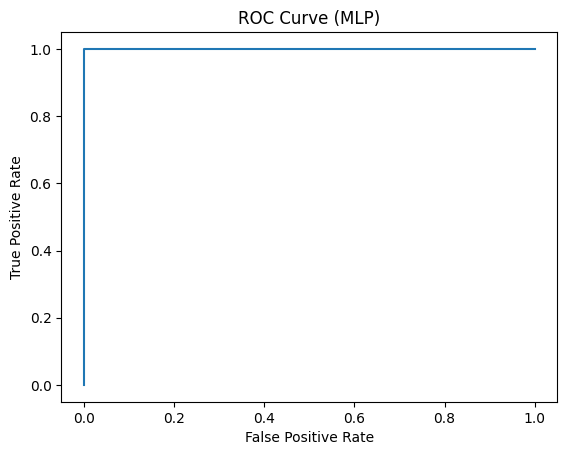


MLP Accuracy: 0.990521327014218

Confusion Matrix (MLP):
[[ 63   2]
 [  0 146]]

Classification Report (MLP):
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        65
           1       0.99      1.00      0.99       146

    accuracy                           0.99       211
   macro avg       0.99      0.98      0.99       211
weighted avg       0.99      0.99      0.99       211


MLP Iterations: 50

Sample probabilities (MLP):
 [0.22215493 0.1742606  0.9991534  0.98867978 0.08740948 0.99579005
 0.99961877 0.99473121 0.24691087 0.25626055]

Train Accuracy (MLP): 0.979381443298969
Test Accuracy (MLP): 0.990521327014218


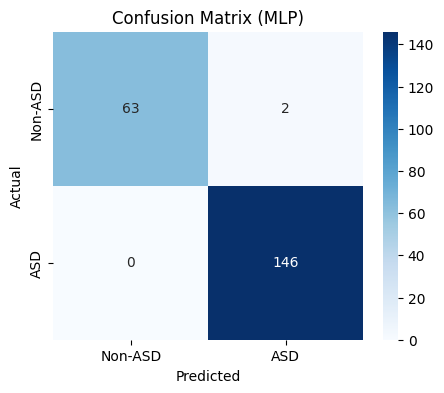

In [12]:
mlp = MLPClassifier(hidden_layer_sizes=(16,8), max_iter=200,
alpha=0.1, early_stopping=True, validation_fraction=0.2)

mlp.fit(X_train, y_train)

y_prob = mlp.predict_proba(X_test)[:,1]
y_pred_mlp = (y_prob > 0.6).astype(int)

from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test, y_prob)
print("\nAUC:", auc(fpr, tpr))
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (MLP)")
plt.show()

print("\nMLP Accuracy:", accuracy_score(y_test, y_pred_mlp))

print("\nConfusion Matrix (MLP):")
print(confusion_matrix(y_test, y_pred_mlp))

print("\nClassification Report (MLP):")
print(classification_report(y_test, y_pred_mlp))

print("\nMLP Iterations:", mlp.n_iter_)
print("\nSample probabilities (MLP):\n", y_prob[:10])

train_pred = mlp.predict(X_train)
print("\nTrain Accuracy (MLP):", accuracy_score(y_train, train_pred))
print("Test Accuracy (MLP):", accuracy_score(y_test, y_pred_mlp))

import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred_mlp)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=['Non-ASD','ASD'],yticklabels=['Non-ASD','ASD'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (MLP)')
plt.show()